# Recap

Models found: ESM2, LM, MIROC6, MM, SR5  |  using: ESM2, LM, MIROC6, MM, SR5
Saved /Users/dianindrawati/Documents/Python/CMIP6_and_ERA5/Fig5_edge_change_fractions_links.csv (one row per link)

Links per variable (summed over models, regions, seasons, scenarios)
source = variable drives the link, target = variable is driven
                  source_links  source_changed  target_links  target_changed  total_links
method  variable                                                                         
granger SM                  95              95            72              72          167
        q                   89              88            57              57          146
        Prw                 85              85           112             110          197
        T                   85              85            89              87          174
        ET                  61              61            75              75          136
        Pr                  61              5

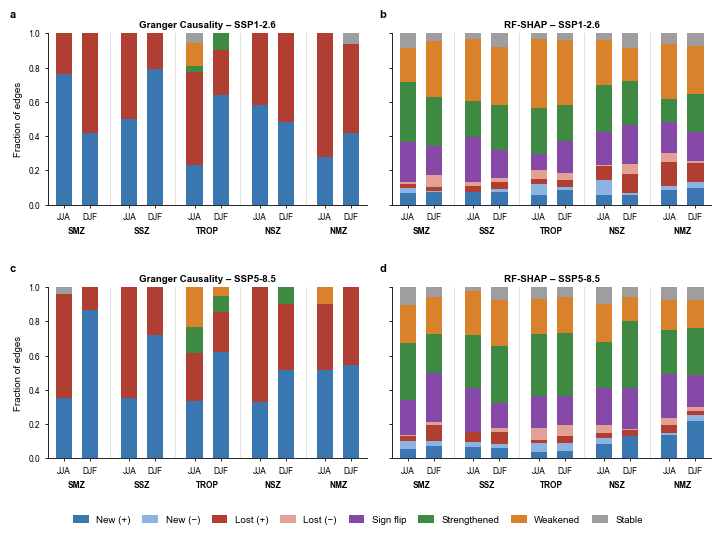

In [5]:
"""
Fig. 5 — fractions of directed hydroclimatic dependency links by change category,
computed in one pass for every scenario × region × season × model × method.

Replaces the manual Excel workflow (Recapitulation_network_changes.xlsx ->
Fraction_interdependence_change.xlsx). The classification logic is identical to
`calculate_network_changes` / `plot_network_on_axis` in the network-plot script,
so the bar fractions and the network panels always agree.

Expected input files (same naming as the network script), e.g.
    Network Change_rev1/jja_shap_granger_comparison_2021-2050_ESM2_SMZ585.csv
    -> {season}_shap_granger_comparison_{period}_{model}_{region}{scenario}.csv
Models are discovered automatically from the file names.

Usage
-----
Edit the SETTINGS block at the bottom of this file, then run it in VS Code
(Run Python File, or run it cell-by-cell in the interactive window).
"""

import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# ──────────────────────────────────────────────────────────────────────────────
# Configuration
# ──────────────────────────────────────────────────────────────────────────────
VARIABLES = ["T", "Prw", "Pr", "ET", "SM", "q"]
VARIABLE_MAPPING = {
    "temperature": "T", "precipitable_water": "Prw", "precipitation": "Pr",
    "evaporation": "ET", "soil_moisture": "SM", "runoff": "q",
}

PERIOD1, PERIOD2 = "2021-2050", "2071-2100"
REGIONS = ["SMZ", "SSZ", "TROP", "NSZ", "NMZ"]          # x-axis order in Fig. 5
SEASONS = ["JJA", "DJF"]
SCENARIOS = {"126": "SSP1-2.6", "585": "SSP5-8.5"}
METHODS = {"granger": "Granger Causality", "shap": "RF-SHAP"}

SIGNIFICANCE_THRESHOLD = 0.05   # Granger (uses the granger_significant column)
DEPENDENCY_THRESHOLD = 0.015    # SHAP edge detection + binary edge presence
CHANGE_THRESHOLD = 0.10         # relative |change| separating stable vs str./weak.

# Category order = stacking order (bottom -> top), as in Fig. 5
CATEGORIES = ["new_positive", "new_negative", "lost_positive", "lost_negative",
              "sign_changed", "strengthened", "weakened", "stable"]
LABELS = {
    "new_positive": "New (+)", "new_negative": "New (\u2212)",
    "lost_positive": "Lost (+)", "lost_negative": "Lost (\u2212)",
    "sign_changed": "Sign flip", "strengthened": "Strengthened",
    "weakened": "Weakened", "stable": "Stable",
}
COLORS = {
    "new_positive": "#3A76AF", "new_negative": "#8DB3E2",
    "lost_positive": "#B03F32", "lost_negative": "#E3A094",
    "sign_changed": "#8649A8", "strengthened": "#3F8A43",
    "weakened": "#D9822B", "stable": "#9E9E9E",
}
# Column codes used in the old Excel table (Fraction_interdependence_change.xlsx)
EXCEL_CODES = {"NP": "new_positive", "NN": "new_negative", "LP": "lost_positive",
               "LN": "lost_negative", "SF": "sign_changed", "S": "strengthened",
               "W": "weakened", "ST": "stable"}
EXCEL_COLUMNS = {"GC126": ("granger", "126"), "RF-SHAP126": ("shap", "126"),
                 "GC585": ("granger", "585"), "RF-SHAP585": ("shap", "585")}

FILE_PATTERN = re.compile(
    r"^(?P<season>[a-z]+)_shap_granger_comparison_(?P<period>\d{4}-\d{4})_"
    r"(?P<model>.+)_(?P<region>" + "|".join(REGIONS) + r")(?P<scenario>"
    + "|".join(SCENARIOS) + r")\.csv$"
)


# ──────────────────────────────────────────────────────────────────────────────
# Edge parsing and classification (same logic as the network-plot script)
# ──────────────────────────────────────────────────────────────────────────────
def parse_edges(df, method):
    """Return list of (source, target, weight) for one method."""
    edges = []
    for _, row in df.iterrows():
        src = VARIABLE_MAPPING.get(row["source_variable"], row["source_variable"])
        tgt = VARIABLE_MAPPING.get(row["target_variable"], row["target_variable"])
        if src == tgt:
            continue
        if method == "granger":
            if bool(row["granger_significant"]):
                p = row["granger_p_value"]
                edges.append((src, tgt, -np.log10(p) if p > 0 else 10.0))
        else:
            dep = abs(row["shap_dependency"])
            if dep >= DEPENDENCY_THRESHOLD:
                edges.append((src, tgt, dep * np.sign(row["shap_direction"])))
    return edges


def adjacency(edges):
    idx = {v: i for i, v in enumerate(VARIABLES)}
    m = np.zeros((len(VARIABLES), len(VARIABLES)))
    for s, t, w in edges:
        m[idx[s], idx[t]] = w
    return m


def classify(m1, m2):
    """Count edges per change category. Every edge present in either period
    falls into exactly one category, so the counts sum to the union size."""
    b1 = np.abs(m1) > DEPENDENCY_THRESHOLD
    b2 = np.abs(m2) > DEPENDENCY_THRESHOLD
    counts = dict.fromkeys(CATEGORIES, 0)

    new = b2 & ~b1
    lost = b1 & ~b2
    both = b1 & b2

    counts["new_positive"] = int(np.sum(new & (m2 > 0)))
    counts["new_negative"] = int(np.sum(new & (m2 < 0)))
    counts["lost_positive"] = int(np.sum(lost & (m1 > 0)))
    counts["lost_negative"] = int(np.sum(lost & (m1 < 0)))

    flip = both & (np.sign(m1) != np.sign(m2))
    same = both & ~flip
    with np.errstate(divide="ignore", invalid="ignore"):
        rel = np.where(same, (np.abs(m2) - np.abs(m1)) / np.abs(m1), 0.0)
    counts["sign_changed"] = int(np.sum(flip))
    counts["strengthened"] = int(np.sum(same & (rel > CHANGE_THRESHOLD)))
    counts["weakened"] = int(np.sum(same & (rel < -CHANGE_THRESHOLD)))
    counts["stable"] = int(np.sum(same & (np.abs(rel) <= CHANGE_THRESHOLD)))
    return counts


def label_links(m1, m2):
    """Same rules as classify(), but returns one row per link:
    (source, target, category). Used for the per-variable summary."""
    out = []
    n = len(VARIABLES)
    for i in range(n):
        for j in range(n):
            a = m1[i:i+1, j:j+1]
            b = m2[i:i+1, j:j+1]
            c = classify(a, b)
            cat = next((k for k, v in c.items() if v), None)
            if cat:
                out.append((VARIABLES[i], VARIABLES[j], cat))
    return out


# ──────────────────────────────────────────────────────────────────────────────
# Batch computation
# ──────────────────────────────────────────────────────────────────────────────
def discover_files(data_dir):
    """Map (scenario, region, season, model) -> {period: path}."""
    found = {}
    for path in Path(data_dir).glob("*.csv"):
        m = FILE_PATTERN.match(path.name)
        if not m:
            continue
        key = (m["scenario"], m["region"], m["season"].upper(), m["model"])
        found.setdefault(key, {})[m["period"]] = path
    return found


def compute_all_counts(data_dir, models=None):
    """Long table: one row per scenario × region × season × model × method."""
    files = discover_files(data_dir)
    if not files:
        raise FileNotFoundError(f"No matching CSV files in {data_dir!r}")
    all_models = sorted({k[3] for k in files})
    models = models or all_models
    print(f"Models found: {', '.join(all_models)}  |  using: {', '.join(models)}")

    rows, links, missing = [], [], []
    for scen in SCENARIOS:
        for region in REGIONS:
            for season in SEASONS:
                for model in models:
                    pair = files.get((scen, region, season, model), {})
                    if PERIOD1 not in pair or PERIOD2 not in pair:
                        missing.append(f"{model} {region}{scen} {season} "
                                       f"(have: {sorted(pair) or 'none'})")
                        continue
                    df1 = pd.read_csv(pair[PERIOD1])
                    df2 = pd.read_csv(pair[PERIOD2])
                    for method in METHODS:
                        m1 = adjacency(parse_edges(df1, method))
                        m2 = adjacency(parse_edges(df2, method))
                        c = classify(m1, m2)
                        rows.append({"scenario": scen, "region": region,
                                     "season": season, "model": model,
                                     "method": method, **c})
                        for src, tgt, cat in label_links(m1, m2):
                            links.append({"scenario": scen, "region": region,
                                          "season": season, "model": model,
                                          "method": method, "source": src,
                                          "target": tgt, "category": cat})
    if missing:
        warnings.warn(f"{len(missing)} combination(s) skipped (missing period file):\n  "
                      + "\n  ".join(missing))
    return pd.DataFrame(rows), pd.DataFrame(links)


def aggregate(per_model):
    """Each model counts equally:
    1) fraction per model = that model's count / that model's total links
    2) bar value = mean of these fractions across models.
    Models with no links at all (total = 0) have no fractions and are left out
    of the mean for that bar; 'n_models' says how many models were averaged."""
    keys = ["scenario", "region", "season", "method"]
    pm = per_model.copy()
    pm["total"] = pm[CATEGORIES].sum(axis=1)
    for c in CATEGORIES:
        pm[f"frac_{c}"] = pm[c] / pm["total"].replace(0, np.nan)   # per-model fraction

    frac_cols = [f"frac_{c}" for c in CATEGORIES]
    agg = pm.groupby(keys, as_index=False)[CATEGORIES + ["total"]].sum()  # counts kept for reference
    means = pm.groupby(keys, as_index=False)[frac_cols].mean()            # equal-weight mean
    agg = agg.merge(means, on=keys)
    agg["n_models"] = pm[pm["total"] > 0].groupby(keys).size().reindex(
        pd.MultiIndex.from_frame(agg[keys]), fill_value=0).values
    return agg


def load_excel_table(path):
    """Read the old hand-made table (cached values) into the aggregate format."""
    raw = pd.read_excel(path).dropna(subset=["Region/Season"])
    raw = raw.rename(columns={raw.columns[1]: "code"})
    rows = []
    for rs, grp in raw.groupby("Region/Season", sort=False):
        region, season = rs.split("-")
        for col, (method, scen) in EXCEL_COLUMNS.items():
            c = {EXCEL_CODES[k]: int(v) for k, v in zip(grp["code"], grp[col])}
            rows.append({"scenario": scen, "region": region, "season": season,
                         "method": method, **c})
    df = pd.DataFrame(rows)
    df["total"] = df[CATEGORIES].sum(axis=1)
    for c in CATEGORIES:
        df[f"frac_{c}"] = df[c] / df["total"].replace(0, np.nan)
    return df


# ──────────────────────────────────────────────────────────────────────────────
# Plot
# ──────────────────────────────────────────────────────────────────────────────
def setup_style():
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Liberation Sans", "Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 7, "axes.labelsize": 7, "axes.titlesize": 7,
        "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 7,
        "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
        "xtick.major.size": 2.5, "ytick.major.size": 2.5,
        "pdf.fonttype": 42, "svg.fonttype": "none",
    })


def plot_panel(ax, agg, method, scen, show_ylabel):
    sub = agg[(agg["method"] == method) & (agg["scenario"] == scen)]
    bar_w, pair_gap, group_gap = 0.62, 1.0, 1.5
    x, ticks, ticklabels, centers = 0.0, [], [], []

    for gi, region in enumerate(REGIONS):
        xs = []
        for season in SEASONS:
            row = sub[(sub["region"] == region) & (sub["season"] == season)]
            bottom = 0.0
            if not row.empty:
                for c in CATEGORIES:
                    v = float(row[f"frac_{c}"].iloc[0] or 0)
                    if v > 0:
                        ax.bar(x, v, bar_w, bottom=bottom, color=COLORS[c],
                               edgecolor="none", zorder=2)
                    bottom += v
            ticks.append(x)
            ticklabels.append(season)
            xs.append(x)
            x += pair_gap
        centers.append(np.mean(xs))
        if gi < len(REGIONS) - 1:
            # midway between this region's last bar and the next region's first bar
            ax.axvline(x - pair_gap + group_gap / 2, color="#DDDDDD", lw=0.6, zorder=0)
        x += group_gap - pair_gap

    ax.set_xticks(ticks)
    ax.set_xticklabels(ticklabels)
    for cx, region in zip(centers, REGIONS):
        ax.text(cx, -0.13, region, transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontweight="bold", fontsize=6)
    ax.set_xlim(ticks[0] - 0.6, ticks[-1] + 0.6)
    ax.set_ylim(0, 1)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    if show_ylabel:
        ax.set_ylabel("Fraction of edges")
    else:
        ax.set_yticklabels([])
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(f"{METHODS[method]} \u2013 {SCENARIOS[scen]}", fontweight="bold", pad=4)


def plot_fig5(agg, save_path="Fig5_edge_change_fractions", width_mm=183, height_mm=135):
    setup_style()
    mm = 1 / 25.4
    fig, axes = plt.subplots(2, 2, figsize=(width_mm * mm, height_mm * mm))
    letters = iter("abcd")
    for r, scen in enumerate(SCENARIOS):
        for c, method in enumerate(METHODS):
            ax = axes[r, c]
            plot_panel(ax, agg, method, scen, show_ylabel=(c == 0))
            ax.text(-0.12 if c == 0 else -0.04, 1.08, next(letters),
                    transform=ax.transAxes, fontweight="bold", fontsize=8, va="bottom")

    handles = [Patch(facecolor=COLORS[c], label=LABELS[c]) for c in CATEGORIES]
    fig.legend(handles=handles, loc="lower center", ncol=8, frameon=False,
               handlelength=1.6, handleheight=0.9, columnspacing=1.2,
               bbox_to_anchor=(0.5, 0.0))
    fig.subplots_adjust(left=0.07, right=0.99, top=0.94, bottom=0.14,
                        hspace=0.48, wspace=0.08)

    for ext in ("png", "pdf"):
        fig.savefig(f"{save_path}.{ext}", dpi=600, bbox_inches="tight", facecolor="white")
    print(f"Saved {save_path}.png / .pdf")
    return fig


def print_summary(agg):
    """Share of links modified (= 1 - stable fraction), models weighted equally,
    then averaged over the bars (regions x seasons)."""
    mod = 100 * (1 - agg["frac_stable"].mean())
    print(f"\nAll regions/seasons/scenarios/methods: {mod:.1f}% of links modified "
          f"(mean over models, then over bars)")
    by = agg.groupby(["method", "scenario"])["frac_stable"].mean()
    print((100 * (1 - by)).round(1).rename("modified_%").to_string())


def variable_summary(links, out):
    """How many links each variable is involved in, as driver (source) and as
    target, for each method. Counts are summed over models, regions, seasons
    and scenarios. 'changed' = every category except stable."""
    lk = links.copy()
    lk["changed"] = lk["category"] != "stable"

    tables = []
    for role in ("source", "target"):
        t = (lk.groupby(["method", role])
               .agg(links=("category", "size"), changed=("changed", "sum"))
               .rename_axis(["method", "variable"]))
        t.columns = [f"{role}_{c}" for c in t.columns]
        tables.append(t)
    summ = pd.concat(tables, axis=1).fillna(0).astype(int)
    summ["total_links"] = summ["source_links"] + summ["target_links"]
    summ = summ.sort_values(["method", "source_links"], ascending=[True, False])
    summ.to_csv(f"{out}_variable_summary.csv")

    # per category, as driver
    by_cat = (lk.pivot_table(index=["method", "source"], columns="category",
                             values="target", aggfunc="size", fill_value=0)
                .reindex(columns=CATEGORIES, fill_value=0))
    by_cat.to_csv(f"{out}_variable_by_category.csv")

    print("\nLinks per variable (summed over models, regions, seasons, scenarios)")
    print("source = variable drives the link, target = variable is driven")
    print(summ.to_string())
    print(f"Saved {out}_variable_summary.csv and {out}_variable_by_category.csv")
    return summ


# ──────────────────────────────────────────────────────────────────────────────
def main(data_dir=None, models=None, from_table=None,
         out="Fig5_edge_change_fractions"):
    if from_table:
        p = Path(from_table)
        agg = load_excel_table(p) if p.suffix in (".xlsx", ".xls") else \
            pd.read_csv(p, dtype={"scenario": str})
    elif data_dir:
        per_model, links = compute_all_counts(data_dir, models)
        links.to_csv(f"{out}_links.csv", index=False)
        print(f"Saved {out}_links.csv (one row per link)")
        variable_summary(links, out)
        agg = aggregate(per_model)
        pm = per_model.copy()
        pm["total"] = pm[CATEGORIES].sum(axis=1)
        for c in CATEGORIES:
            pm[f"frac_{c}"] = pm[c] / pm["total"].replace(0, np.nan)
        pm.to_csv(f"{out}_counts_per_model.csv", index=False)
        agg.to_csv(f"{out}_counts.csv", index=False)
        print(f"Saved {out}_counts.csv and {out}_counts_per_model.csv")
    else:
        raise ValueError("Set DATA_DIR (or FROM_TABLE) in the settings block.")

    print_summary(agg)
    plot_fig5(agg, out)
    plt.show()
    return agg


if __name__ == "__main__":
    # ═════════════ SETTINGS — edit here, then press Run in VS Code ═════════════
    # Relative paths below are resolved from this script's folder, so it works
    # no matter which folder VS Code has open. Absolute paths also work.
    # (__file__ doesn't exist in a notebook / interactive window -> use current folder)
    try:
        BASE = Path(__file__).resolve().parent
    except NameError:
        BASE = Path.cwd()

    # Folder containing files like:
    #   djf_shap_granger_comparison_2021-2050_ESM2_SMZ585.csv
    DATA_DIR = BASE / "Network Change_rev1"

    # Model tags as they appear in the file names (e.g. "ESM2").
    # None = use every model found in DATA_DIR.
    MODELS = None

    # Optional: plot directly from an existing counts table instead of the CSVs
    # (old Excel table or the *_counts.csv this script writes). None = compute.
    FROM_TABLE = None

    # Output name (no extension) -> .png, .pdf, _counts.csv, _counts_per_model.csv
    OUT_NAME = str(BASE / "Fig5_edge_change_fractions")
    # ═══════════════════════════════════════════════════════════════════════════

    agg = main(data_dir=DATA_DIR, models=MODELS, from_table=FROM_TABLE,
               out=OUT_NAME)

# JJA

In [217]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict
import seaborn as sns

def load_combined_data(filepath):
    """Load combined Granger and SHAP data from single CSV file"""
    try:
        df = pd.read_csv(filepath)
        print(f"✓ Successfully loaded data: {len(df)} relationships")
        return df
    except FileNotFoundError:
        print(f"❌ File not found: {filepath}")
        return None
    except Exception as e:
        print(f"❌ Error loading data: {e}")
        return None

def parse_edges_from_combined(df, analysis_type='granger', significance_threshold=0.05, dependency_threshold=0.015):
    """Parse relationships from combined data for either Granger or SHAP analysis"""
    variable_mapping = {
        'temperature': 'T',
        'precipitable_water': 'Prw', 
        'precipitation': 'Pr',
        'evaporation': 'ET',
        'soil_moisture': 'SM',
        'runoff': 'q'
    }
    
    edges = []
    filtered_count = 0
    
    for _, row in df.iterrows():
        source = variable_mapping.get(row['source_variable'], row['source_variable'])
        target = variable_mapping.get(row['target_variable'], row['target_variable'])
        
        if source == target:
            filtered_count += 1
            continue
        
        if analysis_type == 'granger' and row['granger_significant']:
            p_value = row['granger_p_value']
            edge_data = {
                'source': source,
                'target': target,
                'weight': -np.log10(p_value) if p_value > 0 else 10,
                'p_value': p_value,
                'lag': row.get('granger_lag', 1)
            }
            edges.append(edge_data)
            
        elif analysis_type == 'shap':
            dependency = abs(row['shap_dependency'])
            direction = row['shap_direction']
            
            if dependency >= dependency_threshold:
                signed_weight = dependency * np.sign(direction)
                
                edge_data = {
                    'source': source,
                    'target': target,
                    'weight': signed_weight,
                    'dependency': dependency,
                    'direction': direction,
                    'sign': 'positive' if direction > 0 else 'negative'
                }
                edges.append(edge_data)
            else:
                filtered_count += 1
    
    print(f"  Parsed {len(edges)} edges, filtered out {filtered_count} relationships")
    return edges

def create_adjacency_matrix(edges, all_variables=None):
    """Create adjacency matrix from edge data"""
    if all_variables is None:
        all_variables = ['T', 'Prw', 'Pr', 'ET', 'SM', 'q']
    
    n_vars = len(all_variables)
    var_to_idx = {var: i for i, var in enumerate(all_variables)}
    matrix = np.zeros((n_vars, n_vars))
    
    for edge in edges:
        i = var_to_idx[edge['source']]
        j = var_to_idx[edge['target']]
        matrix[i, j] = edge['weight']
    
    return matrix, all_variables

def calculate_network_changes(matrix1, matrix2, variables):
    """Calculate changes between two adjacency matrices"""
    threshold = 0.015
    
    binary1 = (np.abs(matrix1) > threshold).astype(int)
    binary2 = (np.abs(matrix2) > threshold).astype(int)
    
    new_edges = (binary2 == 1) & (binary1 == 0)
    lost_edges = (binary1 == 1) & (binary2 == 0)
    stable_edges = (binary1 == 1) & (binary2 == 1)
    
    sign_changed = np.zeros_like(matrix1, dtype=bool)
    strengthened_edges = np.zeros_like(matrix1, dtype=bool)
    weakened_edges = np.zeros_like(matrix1, dtype=bool)
    
    for i in range(len(variables)):
        for j in range(len(variables)):
            if stable_edges[i, j]:
                old_val = matrix1[i, j]
                new_val = matrix2[i, j]
                
                if np.sign(old_val) != np.sign(new_val):
                    sign_changed[i, j] = True
                elif abs(old_val) > threshold:
                    relative_change = (abs(new_val) - abs(old_val)) / abs(old_val)
                    if relative_change > 0.1:
                        strengthened_edges[i, j] = True
                    elif relative_change < -0.1:
                        weakened_edges[i, j] = True
    
    diff_matrix = matrix2 - matrix1
    
    return {
        'diff_matrix': diff_matrix,
        'new_edges': new_edges,
        'lost_edges': lost_edges,
        'stable_edges': stable_edges,
        'sign_changed': sign_changed,
        'strengthened_edges': strengthened_edges,
        'weakened_edges': weakened_edges,
        'binary1': binary1,
        'binary2': binary2,
        'matrix1': matrix1,
        'matrix2': matrix2
    }

def get_consistent_network_layout(variables):
    """Create consistent layout for network visualization"""
    pos = {
        'T': (0, 1),
        'Prw': (0.87, 0.5),
        'Pr': (0.87, -0.5),
        'ET': (0, -1),
        'SM': (-0.87, -0.5),
        'q': (-0.87, 0.5)
    }
    return pos

def plot_network_on_axis(ax, changes, variables, matrix1, matrix2, analysis_type,
                        period1="2021-2050", period2="2071-2100", arrow_size=25):
    """Plot network changes on a given axis (for subplot)"""
    pos = get_consistent_network_layout(variables)
    
    node_colors_dark = {
        'T': '#E53935', 'Prw': '#1976D2', 'Pr': '#388E3C',
        'ET': '#E91E63', 'SM': '#7B1FA2', 'q': '#5D4037'
    }
    node_colors = [node_colors_dark.get(node, '#666666') for node in variables]
    
    edge_styles = {
        'new_positive': {'color': '#009E73', 'style': '-',  'alpha': 0.9, 'label': 'New (positive)'},
        'new_negative': {'color': '#009E73', 'style': '--', 'alpha': 0.9, 'label': 'New (negative)'},
        'lost_positive': {'color': '#D55E00', 'style': '-', 'alpha': 0.8, 'label': 'Lost (positive)'},
        'lost_negative': {'color': '#D55E00', 'style': '--',  'alpha': 0.8, 'label': 'Lost (negative)'},
        'sign_changed':  {'color': '#CC79A7', 'style': '-.', 'alpha': 0.9, 'label': 'Sign Flip'},
        'strengthened':  {'color': '#0072B2', 'style': '-',  'alpha': 0.85,'label': 'Strengthened'},
        'weakened':      {'color': '#F0E442', 'style': ':',  'alpha': 0.85,'label': 'Weakened'},
        'stable':        {'color': '#999999', 'style': '-',  'alpha': 0.4, 'label': 'Stable'}
    }
    
    def get_edge_width(weight, analysis_type):
        abs_weight = abs(weight)
        if analysis_type == 'granger':
            if abs_weight > 5: return 6
            elif abs_weight > 3: return 4
            elif abs_weight > 2: return 2.5
            else: return 1.5
        else:
            if abs_weight > 0.05: return 6
            elif abs_weight > 0.03: return 4
            elif abs_weight > 0.02: return 2.5
            else: return 1.5
    
    def get_arrow_positions(source_pos, target_pos, node_radius=0.12):
        import math
        dx = target_pos[0] - source_pos[0]
        dy = target_pos[1] - source_pos[1]
        distance = math.sqrt(dx**2 + dy**2)
        if distance == 0:
            return source_pos, target_pos
        ux = dx / distance
        uy = dy / distance
        start_x = source_pos[0] + node_radius * ux
        start_y = source_pos[1] + node_radius * uy
        end_x = target_pos[0] - node_radius * ux
        end_y = target_pos[1] - node_radius * uy
        return (start_x, start_y), (end_x, end_y)
    
    edge_counts = {
        'new_positive': 0, 'new_negative': 0,
        'lost_positive': 0, 'lost_negative': 0,
        'sign_changed': 0, 'strengthened': 0, 'weakened': 0, 'stable': 0
    }
    node_radius = 0.12
    
    # NEW EDGES
    new_positions = np.where(changes['new_edges'])
    for i, j in zip(new_positions[0], new_positions[1]):
        source, target = variables[i], variables[j]
        weight = matrix2[i, j]
        width = get_edge_width(weight, analysis_type)
        edge_type = 'new_positive' if weight > 0 else 'new_negative'
        style = edge_styles[edge_type]
        start_pos, end_pos = get_arrow_positions(pos[source], pos[target], node_radius)
        ax.annotate('', xy=end_pos, xytext=start_pos,
                   arrowprops=dict(arrowstyle='-|>', lw=width,
                                 color=style['color'], alpha=style['alpha'],
                                 linestyle=style['style'],
                                 connectionstyle="arc3,rad=0.1",
                                 shrinkA=0, shrinkB=0, mutation_scale=arrow_size))
        edge_counts[edge_type] += 1

    # LOST EDGES
    lost_positions = np.where(changes['lost_edges'])
    for i, j in zip(lost_positions[0], lost_positions[1]):
        source, target = variables[i], variables[j]
        weight = matrix1[i, j]
        width = get_edge_width(weight, analysis_type)
        edge_type = 'lost_positive' if weight > 0 else 'lost_negative'
        style = edge_styles[edge_type]
        start_pos, end_pos = get_arrow_positions(pos[source], pos[target], node_radius)
        ax.annotate('', xy=end_pos, xytext=start_pos,
                   arrowprops=dict(arrowstyle='-|>', lw=width,
                                 color=style['color'], alpha=style['alpha'],
                                 linestyle=style['style'],
                                 connectionstyle="arc3,rad=0.1",
                                 shrinkA=0, shrinkB=0, mutation_scale=arrow_size))
        edge_counts[edge_type] += 1
    
    # SIGN CHANGED EDGES
    sign_changed_positions = np.where(changes['sign_changed'])
    for i, j in zip(sign_changed_positions[0], sign_changed_positions[1]):
        source, target = variables[i], variables[j]
        new_weight = matrix2[i, j]
        width = get_edge_width(new_weight, analysis_type)
        start_pos, end_pos = get_arrow_positions(pos[source], pos[target], node_radius)
        ax.annotate('', xy=end_pos, xytext=start_pos,
                   arrowprops=dict(arrowstyle='-|>', lw=width,
                                 color=edge_styles['sign_changed']['color'],
                                 alpha=edge_styles['sign_changed']['alpha'],
                                 linestyle=edge_styles['sign_changed']['style'],
                                 connectionstyle="arc3,rad=0.1",
                                 shrinkA=0, shrinkB=0, mutation_scale=arrow_size))
        edge_counts['sign_changed'] += 1
    
    # STRENGTHENED EDGES
    strengthen_positions = np.where(changes['strengthened_edges'])
    for i, j in zip(strengthen_positions[0], strengthen_positions[1]):
        source, target = variables[i], variables[j]
        weight = matrix2[i, j]
        width = get_edge_width(weight, analysis_type)
        start_pos, end_pos = get_arrow_positions(pos[source], pos[target], node_radius)
        ax.annotate('', xy=end_pos, xytext=start_pos,
                   arrowprops=dict(arrowstyle='-|>', lw=width,
                                 color=edge_styles['strengthened']['color'],
                                 alpha=edge_styles['strengthened']['alpha'],
                                 linestyle=edge_styles['strengthened']['style'],
                                 connectionstyle="arc3,rad=0.1",
                                 shrinkA=0, shrinkB=0, mutation_scale=arrow_size))
        edge_counts['strengthened'] += 1
    
    # WEAKENED EDGES
    weaken_positions = np.where(changes['weakened_edges'])
    for i, j in zip(weaken_positions[0], weaken_positions[1]):
        source, target = variables[i], variables[j]
        weight = matrix2[i, j]
        width = get_edge_width(weight, analysis_type)
        start_pos, end_pos = get_arrow_positions(pos[source], pos[target], node_radius)
        ax.annotate('', xy=end_pos, xytext=start_pos,
                   arrowprops=dict(arrowstyle='-|>', lw=width,
                                 color=edge_styles['weakened']['color'],
                                 alpha=edge_styles['weakened']['alpha'],
                                 linestyle=edge_styles['weakened']['style'],
                                 connectionstyle="arc3,rad=0.1",
                                 shrinkA=0, shrinkB=0, mutation_scale=arrow_size))
        edge_counts['weakened'] += 1
    
    # STABLE EDGES
    stable_positions = np.where(changes['stable_edges'] & 
                               ~changes['sign_changed'] &
                               ~changes['strengthened_edges'] & 
                               ~changes['weakened_edges'])
    for i, j in zip(stable_positions[0], stable_positions[1]):
        source, target = variables[i], variables[j]
        weight = matrix2[i, j]
        width = get_edge_width(weight, analysis_type) * 0.7
        start_pos, end_pos = get_arrow_positions(pos[source], pos[target], node_radius)
        ax.annotate('', xy=end_pos, xytext=start_pos,
                   arrowprops=dict(arrowstyle='-|>', lw=width,
                                 color=edge_styles['stable']['color'],
                                 alpha=edge_styles['stable']['alpha'],
                                 linestyle=edge_styles['stable']['style'],
                                 connectionstyle="arc3,rad=0.1",
                                 shrinkA=0, shrinkB=0, mutation_scale=arrow_size))
        edge_counts['stable'] += 1
    
    # Draw nodes
    nx.draw_networkx_nodes(ax=ax, G=None, pos=pos, nodelist=variables,
                          node_color=node_colors, node_size=3000,
                          alpha=1.0, edgecolors='#333333', linewidths=3)
    nx.draw_networkx_labels(ax=ax, G=None, pos=pos, labels={v: v for v in variables},
                           font_size=16, font_weight='bold',
                           font_color='white', font_family='Arial')

    if analysis_type == 'granger':
        subtitle = "(i) Granger Causality"
    else:
        subtitle = "(ii) RF - SHAP"
    ax.set_title(subtitle, fontsize=20, fontweight='bold', pad=20)
    
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.axis('off')
    
    return edge_counts

def plot_combined_network_comparison(df1, df2, variables, period1="2021-2050", period2="2071-2100",
                                    season="JJA", model="NorESM2-MM", region="MidLatitude_N",
                                    arrow_size=40, save_path=None):
    """
    Plot Granger and SHAP networks side by side in subplots
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8), dpi=800)
    
    all_edge_counts = {}
    
    for idx, (analysis_type, ax) in enumerate([('granger', ax1), ('shap', ax2)]):
        print(f"\n🔍 Processing {analysis_type.upper()}...")
        
        edges1 = parse_edges_from_combined(df1, analysis_type)
        edges2 = parse_edges_from_combined(df2, analysis_type)
        
        matrix1, _ = create_adjacency_matrix(edges1, variables)
        matrix2, _ = create_adjacency_matrix(edges2, variables)
        
        changes = calculate_network_changes(matrix1, matrix2, variables)
        
        edge_counts = plot_network_on_axis(
            ax, changes, variables, matrix1, matrix2, analysis_type,
            period1, period2, arrow_size=arrow_size
        )
        
        all_edge_counts[analysis_type] = edge_counts
    
    # ── Complete legend: 8 entries covering all 4 new/lost variants + 4 others ──
    legend_elements = [
        # Row 1: New connections
        plt.Line2D([0], [0], color='#009E73', linewidth=3, linestyle='-',
                   alpha=0.9,  label='New (positive)'),
        plt.Line2D([0], [0], color='#009E73', linewidth=3, linestyle='--',
                   alpha=0.9,  label='New (negative)'),
        # Row 2: Lost connections
        plt.Line2D([0], [0], color='#D55E00', linewidth=3, linestyle='-',
                   alpha=0.8,  label='Lost (positive)'),
        plt.Line2D([0], [0], color='#D55E00', linewidth=3, linestyle='--',
                   alpha=0.8,  label='Lost (negative)'),
        # Row 3: Stable-edge changes
        plt.Line2D([0], [0], color='#CC79A7', linewidth=3, linestyle='-.',
                   alpha=0.9,  label='Sign Flip'),
        plt.Line2D([0], [0], color='#0072B2', linewidth=3, linestyle='-',
                   alpha=0.85, label='Strengthened'),
        # Row 4: Remaining
        plt.Line2D([0], [0], color='#F0E442', linewidth=3, linestyle=':',
                   alpha=0.85, label='Weakened'),
        plt.Line2D([0], [0], color='#999999', linewidth=3, linestyle='-',
                   alpha=0.4,  label='Stable'),
    ]
    
    fig.legend(handles=legend_elements,
               loc='lower center',
               bbox_to_anchor=(0.5, -0.13),
               fontsize=20,
               frameon=False,
               ncol=4)          # 4 columns → 2 clean rows of 4
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.96])
    
    if save_path:
        plt.savefig(save_path, dpi=800, bbox_inches='tight', facecolor='white')
        print(f"\n✓ Saved combined plot: {save_path}")
    
    plt.show()
    
    return all_edge_counts

def main_network_comparison(file1, file2, 
                           period1="2021-2050", period2="2071-2100",
                           season="JJA", model="NorESM2-MM", region="MidLatitude_N",
                           arrow_size=25, debug_mode=False):
    """
    Main function to compare Granger and SHAP networks side by side
    """
    print("🌍 CLIMATE NETWORK TEMPORAL CHANGE ANALYSIS")
    print("=" * 80)
    print(f"Analyzing changes from {period1} to {period2} - {season} season")
    print(f"Model: {model}, Region: {region}")
    
    print(f"\n📊 Loading data...")
    df1 = load_combined_data(file1)
    df2 = load_combined_data(file2)
    
    if df1 is None or df2 is None:
        print("❌ Failed to load data files")
        return
    
    variables = ['T', 'Prw', 'Pr', 'ET', 'SM', 'q']
    
    save_filename = f"combined_temporal_changes_{season.lower()}_{region.lower().replace(' ', '_')}.png"
    
    all_edge_counts = plot_combined_network_comparison(
        df1, df2, variables, period1, period2,
        season, model, region, arrow_size=arrow_size,
        save_path=save_filename
    )
    
    # Print summary
    print(f"\n📊 SUMMARY:")
    print("=" * 50)
    for analysis_type in ['granger', 'shap']:
        edge_counts = all_edge_counts[analysis_type]
        print(f"\n{analysis_type.upper()}:")
        print(f"  New (positive): {edge_counts.get('new_positive', 0)}")
        print(f"  New (negative): {edge_counts.get('new_negative', 0)}")
        print(f"  Lost (positive): {edge_counts.get('lost_positive', 0)}")
        print(f"  Lost (negative): {edge_counts.get('lost_negative', 0)}")
        print(f"  Sign flips:     {edge_counts.get('sign_changed', 0)}")
        print(f"  Strengthened:   {edge_counts['strengthened']}")
        print(f"  Weakened:       {edge_counts['weakened']}")
        print(f"  Stable:         {edge_counts['stable']}")

if __name__ == "__main__":
    file_2021_2050 = "Network Change_rev1/jja_shap_granger_comparison_2021-2050_ESM2_SMZ585.csv"
    file_2071_2100 = "Network Change_rev1/jja_shap_granger_comparison_2071-2100_ESM2_SMZ585.csv"
    
    main_network_comparison(
        file1=file_2021_2050,
        file2=file_2071_2100,
        period1="2021-2050",
        period2="2071-2100", 
        season="JJA",
        model="NorESM2-MM",
        region="MidLatitude_N",
        arrow_size=30,
        debug_mode=False
    )

🌍 CLIMATE NETWORK TEMPORAL CHANGE ANALYSIS
Analyzing changes from 2021-2050 to 2071-2100 - JJA season
Model: NorESM2-MM, Region: MidLatitude_N

📊 Loading data...
✓ Successfully loaded data: 32 relationships
✓ Successfully loaded data: 32 relationships

🔍 Processing GRANGER...
  Parsed 2 edges, filtered out 2 relationships
  Parsed 2 edges, filtered out 2 relationships

🔍 Processing SHAP...
  Parsed 20 edges, filtered out 12 relationships
  Parsed 21 edges, filtered out 11 relationships

✓ Saved combined plot: combined_temporal_changes_jja_midlatitude_n.png



📊 SUMMARY:

GRANGER:
  New (positive): 2
  New (negative): 0
  Lost (positive): 2
  Lost (negative): 0
  Sign flips:     0
  Strengthened:   0
  Weakened:       0
  Stable:         0

SHAP:
  New (positive): 1
  New (negative): 1
  Lost (positive): 0
  Lost (negative): 1
  Sign flips:     7
  Strengthened:   8
  Weakened:       4
  Stable:         0


# DJF

In [163]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict
import seaborn as sns

def load_combined_data(filepath):
    """Load combined Granger and SHAP data from single CSV file"""
    try:
        df = pd.read_csv(filepath)
        print(f"✓ Successfully loaded data: {len(df)} relationships")
        return df
    except FileNotFoundError:
        print(f"❌ File not found: {filepath}")
        return None
    except Exception as e:
        print(f"❌ Error loading data: {e}")
        return None

def parse_edges_from_combined(df, analysis_type='granger', significance_threshold=0.05, dependency_threshold=0.015):
    """Parse relationships from combined data for either Granger or SHAP analysis"""
    variable_mapping = {
        'temperature': 'T',
        'precipitable_water': 'Prw', 
        'precipitation': 'Pr',
        'evaporation': 'ET',
        'soil_moisture': 'SM',
        'runoff': 'q'
    }
    
    edges = []
    filtered_count = 0
    
    for _, row in df.iterrows():
        source = variable_mapping.get(row['source_variable'], row['source_variable'])
        target = variable_mapping.get(row['target_variable'], row['target_variable'])
        
        if source == target:
            filtered_count += 1
            continue
        
        if analysis_type == 'granger' and row['granger_significant']:
            p_value = row['granger_p_value']
            edge_data = {
                'source': source,
                'target': target,
                'weight': -np.log10(p_value) if p_value > 0 else 10,
                'p_value': p_value,
                'lag': row.get('granger_lag', 1)
            }
            edges.append(edge_data)
            
        elif analysis_type == 'shap':
            dependency = abs(row['shap_dependency'])
            direction = row['shap_direction']
            
            if dependency >= dependency_threshold:
                signed_weight = dependency * np.sign(direction)
                
                edge_data = {
                    'source': source,
                    'target': target,
                    'weight': signed_weight,
                    'dependency': dependency,
                    'direction': direction,
                    'sign': 'positive' if direction > 0 else 'negative'
                }
                edges.append(edge_data)
            else:
                filtered_count += 1
    
    print(f"  Parsed {len(edges)} edges, filtered out {filtered_count} relationships")
    return edges

def create_adjacency_matrix(edges, all_variables=None):
    """Create adjacency matrix from edge data"""
    if all_variables is None:
        all_variables = ['T', 'Prw', 'Pr', 'ET', 'SM', 'q']
    
    n_vars = len(all_variables)
    var_to_idx = {var: i for i, var in enumerate(all_variables)}
    matrix = np.zeros((n_vars, n_vars))
    
    for edge in edges:
        i = var_to_idx[edge['source']]
        j = var_to_idx[edge['target']]
        matrix[i, j] = edge['weight']
    
    return matrix, all_variables

def calculate_network_changes(matrix1, matrix2, variables):
    """Calculate changes between two adjacency matrices"""
    #threshold = 0.001
    threshold = 0.015
    
    binary1 = (np.abs(matrix1) > threshold).astype(int)
    binary2 = (np.abs(matrix2) > threshold).astype(int)
    
    new_edges = (binary2 == 1) & (binary1 == 0)
    lost_edges = (binary1 == 1) & (binary2 == 0)
    stable_edges = (binary1 == 1) & (binary2 == 1)
    
    sign_changed = np.zeros_like(matrix1, dtype=bool)
    strengthened_edges = np.zeros_like(matrix1, dtype=bool)
    weakened_edges = np.zeros_like(matrix1, dtype=bool)
    
    for i in range(len(variables)):
        for j in range(len(variables)):
            if stable_edges[i, j]:
                old_val = matrix1[i, j]
                new_val = matrix2[i, j]
                
                if np.sign(old_val) != np.sign(new_val):
                    sign_changed[i, j] = True
                elif abs(old_val) > threshold:
                    relative_change = (abs(new_val) - abs(old_val)) / abs(old_val)
                    if relative_change > 0.1:
                        strengthened_edges[i, j] = True
                    elif relative_change < -0.1:
                        weakened_edges[i, j] = True
    
    diff_matrix = matrix2 - matrix1
    
    return {
        'diff_matrix': diff_matrix,
        'new_edges': new_edges,
        'lost_edges': lost_edges,
        'stable_edges': stable_edges,
        'sign_changed': sign_changed,
        'strengthened_edges': strengthened_edges,
        'weakened_edges': weakened_edges,
        'binary1': binary1,
        'binary2': binary2,
        'matrix1': matrix1,
        'matrix2': matrix2
    }

def get_consistent_network_layout(variables):
    """Create consistent layout for network visualization"""
    pos = {
        'T': (0, 1),
        'Prw': (0.87, 0.5),
        'Pr': (0.87, -0.5),
        'ET': (0, -1),
        'SM': (-0.87, -0.5),
        'q': (-0.87, 0.5)
    }
    return pos

def plot_network_on_axis(ax, changes, variables, matrix1, matrix2, analysis_type,
                        period1="2021-2050", period2="2071-2100", arrow_size=25):
    """Plot network changes on a given axis (for subplot)"""
    pos = get_consistent_network_layout(variables)
    
    node_colors_dark = {
        'T': '#E53935', 'Prw': '#1976D2', 'Pr': '#388E3C',
        'ET': '#E91E63', 'SM': '#7B1FA2', 'q': '#5D4037'
    }
    node_colors = [node_colors_dark.get(node, '#666666') for node in variables]
    
    edge_styles = {
        'new_positive': {'color': '#009E73', 'style': '-',  'alpha': 0.9, 'label': 'New (positive)'},
        'new_negative': {'color': '#009E73', 'style': '--', 'alpha': 0.9, 'label': 'New (negative)'},
        'lost_positive': {'color': '#D55E00', 'style': '-', 'alpha': 0.8, 'label': 'Lost (positive)'},
        'lost_negative': {'color': '#D55E00', 'style': '--',  'alpha': 0.8, 'label': 'Lost (negative)'},
        'sign_changed':  {'color': '#CC79A7', 'style': '-.', 'alpha': 0.9, 'label': 'Sign Flip'},
        'strengthened':  {'color': '#0072B2', 'style': '-',  'alpha': 0.85,'label': 'Strengthened'},
        'weakened':      {'color': '#F0E442', 'style': ':',  'alpha': 0.85,'label': 'Weakened'},
        'stable':        {'color': '#999999', 'style': '-',  'alpha': 0.4, 'label': 'Stable'}
    }
    
    def get_edge_width(weight, analysis_type):
        abs_weight = abs(weight)
        if analysis_type == 'granger':
            if abs_weight > 5: return 6
            elif abs_weight > 3: return 4
            elif abs_weight > 2: return 2.5
            else: return 1.5
        else:
            if abs_weight > 0.05: return 6
            elif abs_weight > 0.03: return 4
            elif abs_weight > 0.02: return 2.5
            else: return 1.5
    
    def get_arrow_positions(source_pos, target_pos, node_radius=0.12):
        import math
        dx = target_pos[0] - source_pos[0]
        dy = target_pos[1] - source_pos[1]
        distance = math.sqrt(dx**2 + dy**2)
        if distance == 0:
            return source_pos, target_pos
        ux = dx / distance
        uy = dy / distance
        start_x = source_pos[0] + node_radius * ux
        start_y = source_pos[1] + node_radius * uy
        end_x = target_pos[0] - node_radius * ux
        end_y = target_pos[1] - node_radius * uy
        return (start_x, start_y), (end_x, end_y)
    
    edge_counts = {
        'new_positive': 0, 'new_negative': 0,
        'lost_positive': 0, 'lost_negative': 0,
        'sign_changed': 0, 'strengthened': 0, 'weakened': 0, 'stable': 0
    }
    node_radius = 0.12
    
    # NEW EDGES
    new_positions = np.where(changes['new_edges'])
    for i, j in zip(new_positions[0], new_positions[1]):
        source, target = variables[i], variables[j]
        weight = matrix2[i, j]
        width = get_edge_width(weight, analysis_type)
        edge_type = 'new_positive' if weight > 0 else 'new_negative'
        style = edge_styles[edge_type]
        start_pos, end_pos = get_arrow_positions(pos[source], pos[target], node_radius)
        ax.annotate('', xy=end_pos, xytext=start_pos,
                   arrowprops=dict(arrowstyle='-|>', lw=width,
                                 color=style['color'], alpha=style['alpha'],
                                 linestyle=style['style'],
                                 connectionstyle="arc3,rad=0.1",
                                 shrinkA=0, shrinkB=0, mutation_scale=arrow_size))
        edge_counts[edge_type] += 1

    # LOST EDGES
    lost_positions = np.where(changes['lost_edges'])
    for i, j in zip(lost_positions[0], lost_positions[1]):
        source, target = variables[i], variables[j]
        weight = matrix1[i, j]
        width = get_edge_width(weight, analysis_type)
        edge_type = 'lost_positive' if weight > 0 else 'lost_negative'
        style = edge_styles[edge_type]
        start_pos, end_pos = get_arrow_positions(pos[source], pos[target], node_radius)
        ax.annotate('', xy=end_pos, xytext=start_pos,
                   arrowprops=dict(arrowstyle='-|>', lw=width,
                                 color=style['color'], alpha=style['alpha'],
                                 linestyle=style['style'],
                                 connectionstyle="arc3,rad=0.1",
                                 shrinkA=0, shrinkB=0, mutation_scale=arrow_size))
        edge_counts[edge_type] += 1
    
    # SIGN CHANGED EDGES
    sign_changed_positions = np.where(changes['sign_changed'])
    for i, j in zip(sign_changed_positions[0], sign_changed_positions[1]):
        source, target = variables[i], variables[j]
        new_weight = matrix2[i, j]
        width = get_edge_width(new_weight, analysis_type)
        start_pos, end_pos = get_arrow_positions(pos[source], pos[target], node_radius)
        ax.annotate('', xy=end_pos, xytext=start_pos,
                   arrowprops=dict(arrowstyle='-|>', lw=width,
                                 color=edge_styles['sign_changed']['color'],
                                 alpha=edge_styles['sign_changed']['alpha'],
                                 linestyle=edge_styles['sign_changed']['style'],
                                 connectionstyle="arc3,rad=0.1",
                                 shrinkA=0, shrinkB=0, mutation_scale=arrow_size))
        edge_counts['sign_changed'] += 1
    
    # STRENGTHENED EDGES
    strengthen_positions = np.where(changes['strengthened_edges'])
    for i, j in zip(strengthen_positions[0], strengthen_positions[1]):
        source, target = variables[i], variables[j]
        weight = matrix2[i, j]
        width = get_edge_width(weight, analysis_type)
        start_pos, end_pos = get_arrow_positions(pos[source], pos[target], node_radius)
        ax.annotate('', xy=end_pos, xytext=start_pos,
                   arrowprops=dict(arrowstyle='-|>', lw=width,
                                 color=edge_styles['strengthened']['color'],
                                 alpha=edge_styles['strengthened']['alpha'],
                                 linestyle=edge_styles['strengthened']['style'],
                                 connectionstyle="arc3,rad=0.1",
                                 shrinkA=0, shrinkB=0, mutation_scale=arrow_size))
        edge_counts['strengthened'] += 1
    
    # WEAKENED EDGES
    weaken_positions = np.where(changes['weakened_edges'])
    for i, j in zip(weaken_positions[0], weaken_positions[1]):
        source, target = variables[i], variables[j]
        weight = matrix2[i, j]
        width = get_edge_width(weight, analysis_type)
        start_pos, end_pos = get_arrow_positions(pos[source], pos[target], node_radius)
        ax.annotate('', xy=end_pos, xytext=start_pos,
                   arrowprops=dict(arrowstyle='-|>', lw=width,
                                 color=edge_styles['weakened']['color'],
                                 alpha=edge_styles['weakened']['alpha'],
                                 linestyle=edge_styles['weakened']['style'],
                                 connectionstyle="arc3,rad=0.1",
                                 shrinkA=0, shrinkB=0, mutation_scale=arrow_size))
        edge_counts['weakened'] += 1
    
    # STABLE EDGES
    stable_positions = np.where(changes['stable_edges'] & 
                               ~changes['sign_changed'] &
                               ~changes['strengthened_edges'] & 
                               ~changes['weakened_edges'])
    for i, j in zip(stable_positions[0], stable_positions[1]):
        source, target = variables[i], variables[j]
        weight = matrix2[i, j]
        width = get_edge_width(weight, analysis_type) * 0.7
        start_pos, end_pos = get_arrow_positions(pos[source], pos[target], node_radius)
        ax.annotate('', xy=end_pos, xytext=start_pos,
                   arrowprops=dict(arrowstyle='-|>', lw=width,
                                 color=edge_styles['stable']['color'],
                                 alpha=edge_styles['stable']['alpha'],
                                 linestyle=edge_styles['stable']['style'],
                                 connectionstyle="arc3,rad=0.1",
                                 shrinkA=0, shrinkB=0, mutation_scale=arrow_size))
        edge_counts['stable'] += 1
    
    # Draw nodes
    nx.draw_networkx_nodes(ax=ax, G=None, pos=pos, nodelist=variables,
                          node_color=node_colors, node_size=3000,
                          alpha=1.0, edgecolors='#333333', linewidths=3)
    nx.draw_networkx_labels(ax=ax, G=None, pos=pos, labels={v: v for v in variables},
                           font_size=16, font_weight='bold',
                           font_color='white', font_family='Arial')

    if analysis_type == 'granger':
        subtitle = "(i) Granger Causality"
    else:
        subtitle = "(ii) RF - SHAP"
    ax.set_title(subtitle, fontsize=20, fontweight='bold', pad=20)
    
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.axis('off')
    
    return edge_counts

def plot_combined_network_comparison(df1, df2, variables, period1="2021-2050", period2="2071-2100",
                                    season="DJF", model="NorESM2-MM", region="MidLatitude_N",
                                    arrow_size=40, save_path=None):
    """
    Plot Granger and SHAP networks side by side in subplots
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8), dpi=800)
    
    all_edge_counts = {}
    
    for idx, (analysis_type, ax) in enumerate([('granger', ax1), ('shap', ax2)]):
        print(f"\n🔍 Processing {analysis_type.upper()}...")
        
        edges1 = parse_edges_from_combined(df1, analysis_type)
        edges2 = parse_edges_from_combined(df2, analysis_type)
        
        matrix1, _ = create_adjacency_matrix(edges1, variables)
        matrix2, _ = create_adjacency_matrix(edges2, variables)
        
        changes = calculate_network_changes(matrix1, matrix2, variables)
        
        edge_counts = plot_network_on_axis(
            ax, changes, variables, matrix1, matrix2, analysis_type,
            period1, period2, arrow_size=arrow_size
        )
        
        all_edge_counts[analysis_type] = edge_counts
    
    # ── Complete legend: 8 entries covering all 4 new/lost variants + 4 others ──
    legend_elements = [
        # Row 1: New connections
        plt.Line2D([0], [0], color='#009E73', linewidth=3, linestyle='-',
                   alpha=0.9,  label='New (positive)'),
        plt.Line2D([0], [0], color='#009E73', linewidth=3, linestyle='--',
                   alpha=0.9,  label='New (negative)'),
        # Row 2: Lost connections
        plt.Line2D([0], [0], color='#D55E00', linewidth=3, linestyle='-',
                   alpha=0.8,  label='Lost (positive)'),
        plt.Line2D([0], [0], color='#D55E00', linewidth=3, linestyle='--',
                   alpha=0.8,  label='Lost (negative)'),
        # Row 3: Stable-edge changes
        plt.Line2D([0], [0], color='#CC79A7', linewidth=3, linestyle='-.',
                   alpha=0.9,  label='Sign Flip'),
        plt.Line2D([0], [0], color='#0072B2', linewidth=3, linestyle='-',
                   alpha=0.85, label='Strengthened'),
        # Row 4: Remaining
        plt.Line2D([0], [0], color='#F0E442', linewidth=3, linestyle=':',
                   alpha=0.85, label='Weakened'),
        plt.Line2D([0], [0], color='#999999', linewidth=3, linestyle='-',
                   alpha=0.4,  label='Stable'),
    ]
    
    fig.legend(handles=legend_elements,
               loc='lower center',
               bbox_to_anchor=(0.5, -0.13),
               fontsize=17,
               frameon=False,
               ncol=4)          # 4 columns → 2 clean rows of 4
    
    #plt.suptitle(f"Network Changes: {period1} → {period2} ({season}, {region})",
    #            fontsize=22, fontweight='bold', y=0.98)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.96])
    
    if save_path:
        plt.savefig(save_path, dpi=800, bbox_inches='tight', facecolor='white')
        print(f"\n✓ Saved combined plot: {save_path}")
    
    plt.show()
    
    return all_edge_counts

def main_network_comparison(file1, file2, 
                           period1="2021-2050", period2="2071-2100",
                           season="DJF", model="NorESM2-MM", region="MidLatitude_N",
                           arrow_size=25, debug_mode=False):
    """
    Main function to compare Granger and SHAP networks side by side
    """
    print("🌍 CLIMATE NETWORK TEMPORAL CHANGE ANALYSIS")
    print("=" * 80)
    print(f"Analyzing changes from {period1} to {period2} - {season} season")
    print(f"Model: {model}, Region: {region}")
    
    print(f"\n📊 Loading data...")
    df1 = load_combined_data(file1)
    df2 = load_combined_data(file2)
    
    if df1 is None or df2 is None:
        print("❌ Failed to load data files")
        return
    
    variables = ['T', 'Prw', 'Pr', 'ET', 'SM', 'q']
    
    save_filename = f"combined_temporal_changes_{season.lower()}_{region.lower().replace(' ', '_')}.png"
    
    all_edge_counts = plot_combined_network_comparison(
        df1, df2, variables, period1, period2,
        season, model, region, arrow_size=arrow_size,
        save_path=save_filename
    )
    
    # Print summary
    print(f"\n📊 SUMMARY:")
    print("=" * 50)
    for analysis_type in ['granger', 'shap']:
        edge_counts = all_edge_counts[analysis_type]
        print(f"\n{analysis_type.upper()}:")
        print(f"  New (positive): {edge_counts.get('new_positive', 0)}")
        print(f"  New (negative): {edge_counts.get('new_negative', 0)}")
        print(f"  Lost (positive): {edge_counts.get('lost_positive', 0)}")
        print(f"  Lost (negative): {edge_counts.get('lost_negative', 0)}")
        print(f"  Sign flips:     {edge_counts.get('sign_changed', 0)}")
        print(f"  Strengthened:   {edge_counts['strengthened']}")
        print(f"  Weakened:       {edge_counts['weakened']}")
        print(f"  Stable:         {edge_counts['stable']}")

if __name__ == "__main__":
    file_2021_2050 = "Network Change_rev1/djf_shap_granger_comparison_2021-2050_ESM2_SMZ585.csv"
    file_2071_2100 = "Network Change_rev1/djf_shap_granger_comparison_2071-2100_ESM2_SMZ585.csv"
    
    main_network_comparison(
        file1=file_2021_2050,
        file2=file_2071_2100,
        period1="2021-2050",
        period2="2071-2100", 
        season="DJF",
        model="NorESM2-MM",
        region="MidLatitude_N",
        arrow_size=30,
        debug_mode=False
    )

🌍 CLIMATE NETWORK TEMPORAL CHANGE ANALYSIS
Analyzing changes from 2021-2050 to 2071-2100 - DJF season
Model: NorESM2-MM, Region: MidLatitude_N

📊 Loading data...
✓ Successfully loaded data: 32 relationships
✓ Successfully loaded data: 32 relationships

🔍 Processing GRANGER...
  Parsed 0 edges, filtered out 2 relationships
  Parsed 3 edges, filtered out 2 relationships

🔍 Processing SHAP...
  Parsed 19 edges, filtered out 13 relationships
  Parsed 22 edges, filtered out 10 relationships

✓ Saved combined plot: combined_temporal_changes_djf_midlatitude_n.png



📊 SUMMARY:

GRANGER:
  New (positive): 3
  New (negative): 0
  Lost (positive): 0
  Lost (negative): 0
  Sign flips:     0
  Strengthened:   0
  Weakened:       0
  Stable:         0

SHAP:
  New (positive): 3
  New (negative): 1
  Lost (positive): 1
  Lost (negative): 0
  Sign flips:     6
  Strengthened:   4
  Weakened:       6
  Stable:         2
